# Stock Price Prediction: Linear Regression -> LSTM

Uses `data-02-stock_daily - data-02-stock_daily.csv` (must be in the same folder): daily Google (GOOG) stock history with the columns
*Open, High, Low, Volume, Close*. The model predicts the **next day's Close** from today's Open/High/Low/Volume.

1. **Baseline** - a linear model predicts the next day's value from today's features
2. **Improved** - an **LSTM** reads a window of the previous 5 days (a sequence), which suits time-series data

Both models use Min-Max scaling and a chronological 70/30 train/test split.

Before shift:
[0.97333581 0.97543152 1.         0.11112306] [0.98831302]
[0.95690035 0.95988111 0.9803545  0.14250246] [0.97785024]
After shift:
[0.97333581 0.97543152 1.         0.11112306] [0.97785024]
[0.95690035 0.95988111 0.9803545  0.14250246] [0.96645463]


C:\Users\User\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 3.8039e-04 - mse: 3.8039e-04 
Test Loss, Test MSE: [0.0003803911677096039, 0.0003803911677096039]
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


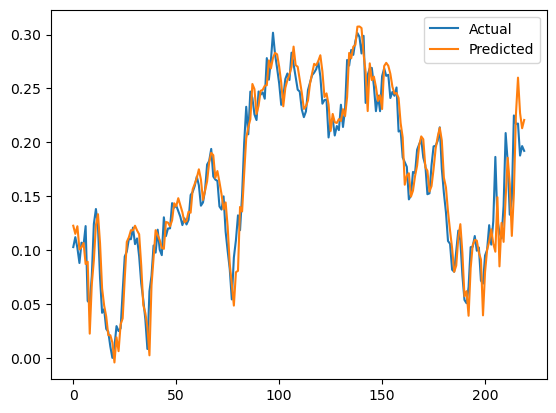

In [5]:
# Baseline: a single linear neuron predicts tomorrow's value from today's features.
from keras.models import Sequential
from keras.layers import Dense
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# Load dataset
xy = np.loadtxt("data-02-stock_daily - data-02-stock_daily.csv", delimiter=',')

# Normalize data
# scale every column to [0, 1] - Volume is in the millions while prices are in the hundreds, so unscaled data would be dominated by Volume
scaler = MinMaxScaler(feature_range=(0, 1))
xy = scaler.fit_transform(xy)

# Split features and labels
x_data = xy[:, 0:-1]   # all columns except last
y_data = xy[:, [-1]]   # last column only

print("Before shift:")
print(x_data[0], y_data[0])
print(x_data[1], y_data[1])

# Align data for "predict tomorrow"
x_data = np.delete(x_data, -1, axis=0)   # remove last row
y_data = np.delete(y_data, 0, axis=0)    # remove first row

print("After shift:")
print(x_data[0], y_data[0])
print(x_data[1], y_data[1])

# Train-test split
# chronological 70/30 split (no shuffling for time-series data)
train_size = int(len(x_data) * 0.7)
x_train, x_test = x_data[:train_size], x_data[train_size:]
y_train, y_test = y_data[:train_size], y_data[train_size:]

# Build model
model = Sequential()
model.add(Dense(units=1, input_dim=x_train.shape[1]))  # auto-detect feature count
model.compile(loss='mse', optimizer='adam', metrics=['mse'])

# Train model
model.fit(x_train, y_train, epochs=200, verbose=0)

# Evaluate
results = model.evaluate(x_test, y_test, verbose=1)
print("Test Loss, Test MSE:", results)

# Predictions
predictions = model.predict(x_test)

# Plot results
plt.plot(y_test, label='Actual')
plt.plot(predictions, label='Predicted')
plt.legend()
plt.show()


C:\Users\User\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 8.7908e-04 
Test Loss: 0.0008790793945081532
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step


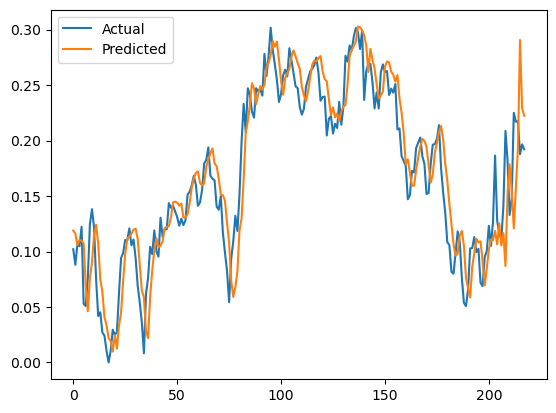

In [6]:
# Improved model: an LSTM looks at the last 5 days (a sequence) instead of a single day.
# improveed code
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense, LSTM

# Load dataset
xy = np.loadtxt("data-02-stock_daily - data-02-stock_daily.csv", delimiter=',')

# Normalize data
scaler = MinMaxScaler(feature_range=(0, 1))
xy = scaler.fit_transform(xy)

# Split features and labels
x_data = xy[:, 0:-1]   # all columns except last
y_data = xy[:, [-1]]   # last column only

# Align data for "predict tomorrow"
x_data = np.delete(x_data, -1, axis=0)   # remove last row
y_data = np.delete(y_data, 0, axis=0)    # remove first row

# Convert to sequences (time-series windows)
# sliding window: X = days [i, i+time_steps), y = the value on the following day
def create_dataset(x, y, time_steps=5):
    Xs, Ys = [], []
    for i in range(len(x) - time_steps):
        Xs.append(x[i:(i+time_steps)])
        Ys.append(y[i+time_steps])
    return np.array(Xs), np.array(Ys)

time_steps = 5
x_seq, y_seq = create_dataset(x_data, y_data, time_steps)

# Train-test split
# chronological 70/30 split
train_size = int(len(x_seq) * 0.7)
x_train, x_test = x_seq[:train_size], x_seq[train_size:]
y_train, y_test = y_seq[:train_size], y_seq[train_size:]

# Reshape for LSTM [samples, time_steps, features]
x_train = x_train.reshape((x_train.shape[0], time_steps, x_train.shape[2]))
x_test = x_test.reshape((x_test.shape[0], time_steps, x_test.shape[2]))

# Build LSTM model
model = Sequential()
# LSTM layer with 50 memory units: reads the 5-day sequence and outputs one summary vector
model.add(LSTM(units=50, return_sequences=False, input_shape=(time_steps, x_train.shape[2])))
# regression head: the predicted value
